In [ ]:
import sys
!{sys.executable} -m pip install mne > /dev/null
!{sys.executable} -m pip install nilearn > /dev/null
!{sys.executable} -m pip install nibabel > /dev/null
!{sys.executable} -m pip install seaborn > /dev/null

# @title Install dependencies

In [ ]:
#python stuffs
import pickle
import numpy as np
import glob
import re
import os
import scipy, sklearn
import numpy as np
import os.path as op
import pandas as pd
from scipy.signal import find_peaks



# plotting stuffs
import matplotlib.pyplot as plt
import seaborn as sns

#neuroimaging stuffs
import mne
import nibabel as nib
from nilearn import plotting
from nilearn import surface
from nilearn.image import load_img


import warnings
warnings.filterwarnings('ignore')


# @title Importage

ModuleNotFoundError: No module named 'mne'

In [ ]:
import sys
!{sys.executable} -m pip install gdown==v4.6.3


  Attempting uninstall: gdown
    Found existing installation: gdown 4.6.0
    Uninstalling gdown-4.6.0:
      Successfully uninstalled gdown-4.6.0


In [ ]:
import gdown
gdown.download_folder('https://drive.google.com/drive/folders/17fRoxjo74McYyJd58yB5fl_Zgblb9aSn', quiet=True)

# @title Download sub-01 data

In [ ]:
data_path =  '/content/sub-01/ieeg/sub-01_run-01_epoched.fif'
epoched = mne.read_epochs(data_path, verbose=False);
evoked = epoched.average()


ts_args = dict(xlim=[-0.1,0.3])

ch, peak_locs1 = evoked.get_peak(ch_type='seeg', tmin=-0.05, tmax=0.01)
ch, peak_locs2 = evoked.get_peak(ch_type='seeg', tmin=0.01, tmax=0.02)
ch, peak_locs3 = evoked.get_peak(ch_type='seeg', tmin=0.03, tmax=0.05)
ch, peak_locs4 = evoked.get_peak(ch_type='seeg', tmin=0.07, tmax=0.15)
ch, peak_locs5 = evoked.get_peak(ch_type='seeg', tmin=0.15, tmax=0.20)

times = [peak_locs1, peak_locs2, peak_locs3, peak_locs4, peak_locs5]


plot = evoked.plot_joint(ts_args=ts_args, times=times);


(185, 1001)
No projector specified for this dataset. Please consider the method self.add_proj.


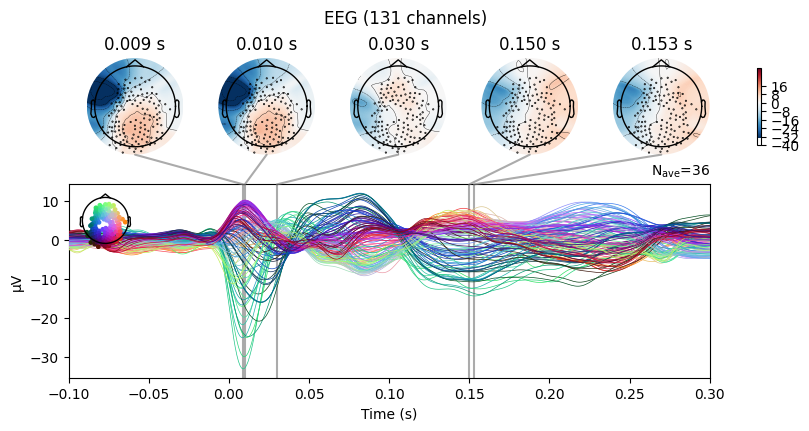

In [ ]:
data_path =  '/content/sub-01/eeg/sub-01_run-01_epoched.fif'
epoched = mne.read_epochs(data_path, verbose=False);
evoked = epoched.average()
data_dimensions = evoked.data.shape
print(data_dimensions)
ts_args = dict(xlim=[-0.1,0.3])

ch, peak_locs1 = evoked.get_peak(ch_type='eeg', tmin=-0.05, tmax=0.01)
ch, peak_locs2 = evoked.get_peak(ch_type='eeg', tmin=0.01, tmax=0.02)
ch, peak_locs3 = evoked.get_peak(ch_type='eeg', tmin=0.03, tmax=0.05)
ch, peak_locs4 = evoked.get_peak(ch_type='eeg', tmin=0.07, tmax=0.15)
ch, peak_locs5 = evoked.get_peak(ch_type='eeg', tmin=0.15, tmax=0.20)

times = [peak_locs1, peak_locs2, peak_locs3, peak_locs4, peak_locs5]


plot = evoked.plot_joint(ts_args=ts_args, times=times);


Text(0.5, 1.0, 'eigenvector#3 variance explained 3.66%')

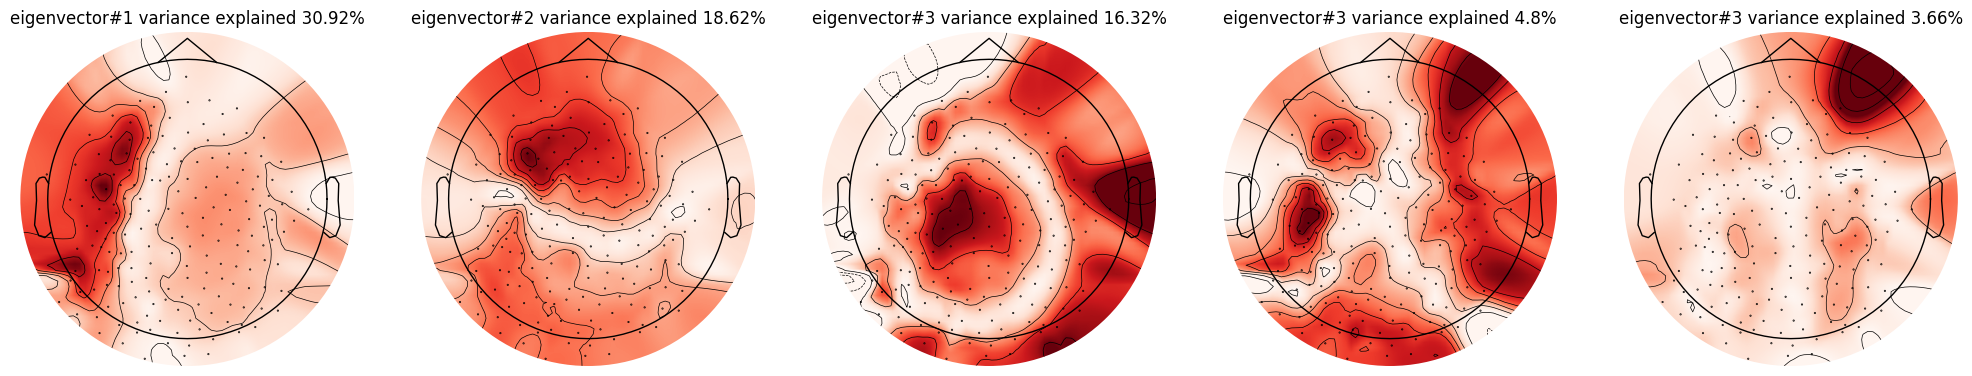

In [ ]:
plt.style.use('default')

xmin = -0.05
xmax = 0.5

A = evoked.data[:,np.where(evoked.times==xmin)[0][0]:np.where(evoked.times==xmax)[0][0]]
U,S,V = np.linalg.svd(A)
S_PC = (100*S)/(np.sum(S))



fig, axes = plt.subplots(figsize=(25, 5), nrows=1, ncols=5)

mne.viz.plot_topomap(np.abs(U[:, 0]), epoched.info, show=False, axes=axes[0])
axes[0].set_title('eigenvector#' + str(1) + ' variance explained ' + str(round(S_PC[0],2)) + '%')
mne.viz.plot_topomap(np.abs(U[:, 1]), epoched.info, show=False, axes=axes[1])
axes[1].set_title('eigenvector#' + str(2) + ' variance explained ' + str(round(S_PC[1],2)) + '%')
mne.viz.plot_topomap(np.abs(U[:, 2]), epoched.info, show=False, axes=axes[2])
axes[2].set_title('eigenvector#' + str(3) + ' variance explained ' + str(round(S_PC[2],2)) + '%')
mne.viz.plot_topomap(np.abs(U[:, 3]), epoched.info, show=False, axes=axes[3])
axes[3].set_title('eigenvector#' + str(3) + ' variance explained ' + str(round(S_PC[3],2)) + '%')
mne.viz.plot_topomap(np.abs(U[:, 4]), epoched.info, show=False, axes=axes[4])
axes[4].set_title('eigenvector#' + str(3) + ' variance explained ' + str(round(S_PC[4],2)) + '%')

In [ ]:
#Here you can loop over the component (the first 3)
comp_n=0
start_tp = np.where(epoched.times ==xmin)[0][0]
end_tp = np.where(epoched.times ==xmax)[0][0]


max_similairty = np.zeros((epoched._data.shape[0]))
for trial in range(epoched._data.shape[0]):
  similarity = []

  for tp in range(start_tp,end_tp):
      similarity.append(1 - scipy.spatial.distance.cosine(np.abs(U[:, comp_n]), np.abs(epoched._data[trial,:,tp])))

  similarity = np.array(similarity)
  max_similairty[trial] = np.where(similarity == np.max(similarity))[0][0]

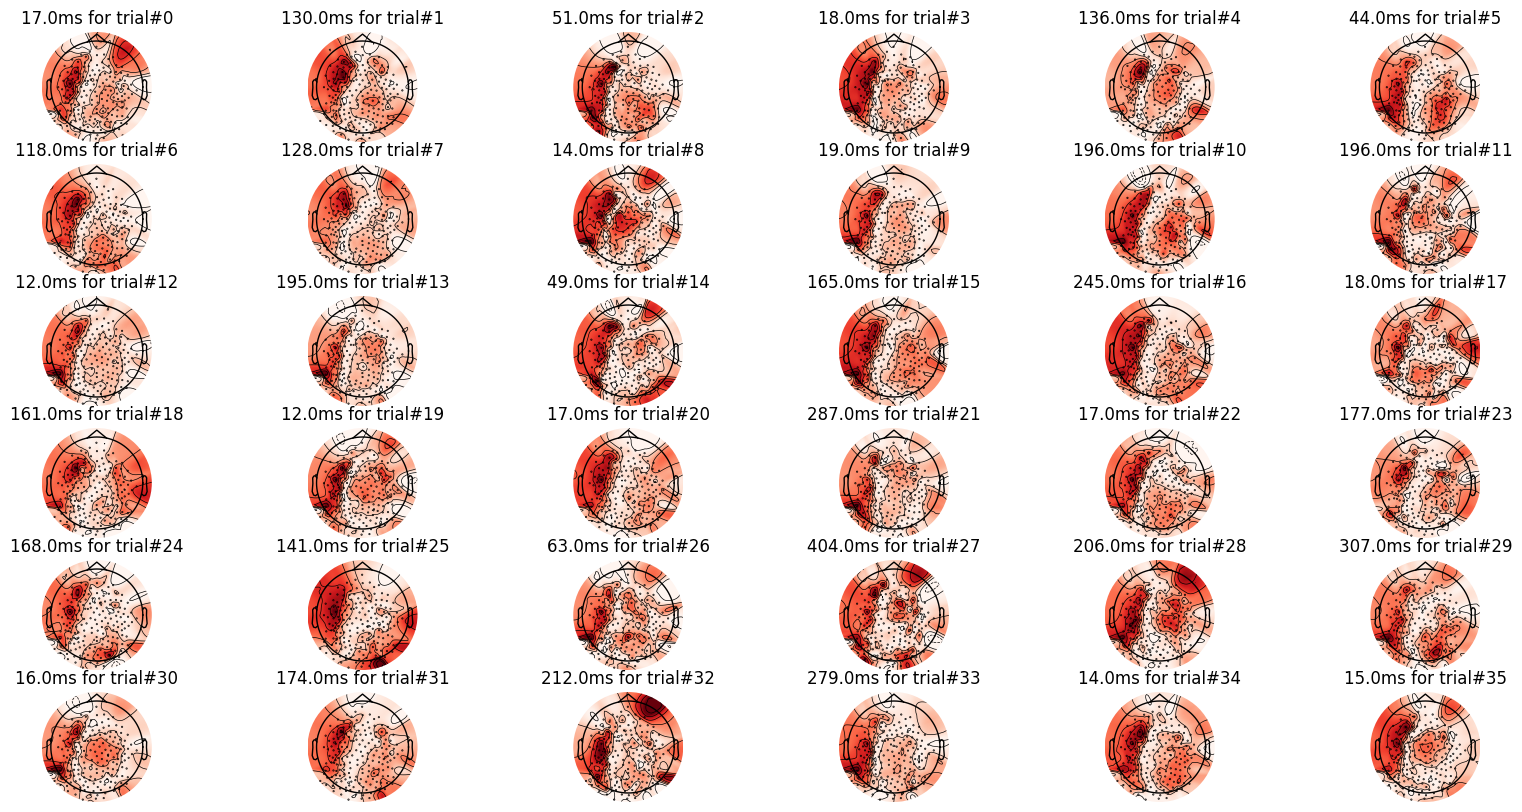

In [ ]:
nrows = 6
ncols=6

fig, axes = plt.subplots(figsize=(20, 10), nrows=nrows, ncols=ncols)

trial=0

for axes_row in range(nrows):
    for ax in range(ncols):
        mne.viz.plot_topomap(np.abs(epoched._data[trial,:,int(max_similairty[trial]+start_tp)]), epoched.info, show=False, axes=axes[axes_row,ax])
        axes[axes_row,ax].set_title(str(epoched.times[int(max_similairty[trial] + start_tp)]*1000) + 'ms for trial#' + str(trial))

        trial=trial+1

    trial=trial

File: sub-01_run-05_epoched.fif, Data shape: (34, 185, 1001)
File: sub-01_run-06_epoched.fif, Data shape: (35, 185, 1001)
File: sub-01_run-03_epoched.fif, Data shape: (35, 185, 1001)
File: sub-01_run-04_epoched.fif, Data shape: (37, 185, 1001)
File: sub-01_run-01_epoched.fif, Data shape: (36, 185, 1001)
File: sub-01_run-02_epoched.fif, Data shape: (32, 185, 1001)
File: sub-01_run-07_epoched.fif, Data shape: (36, 185, 1001)


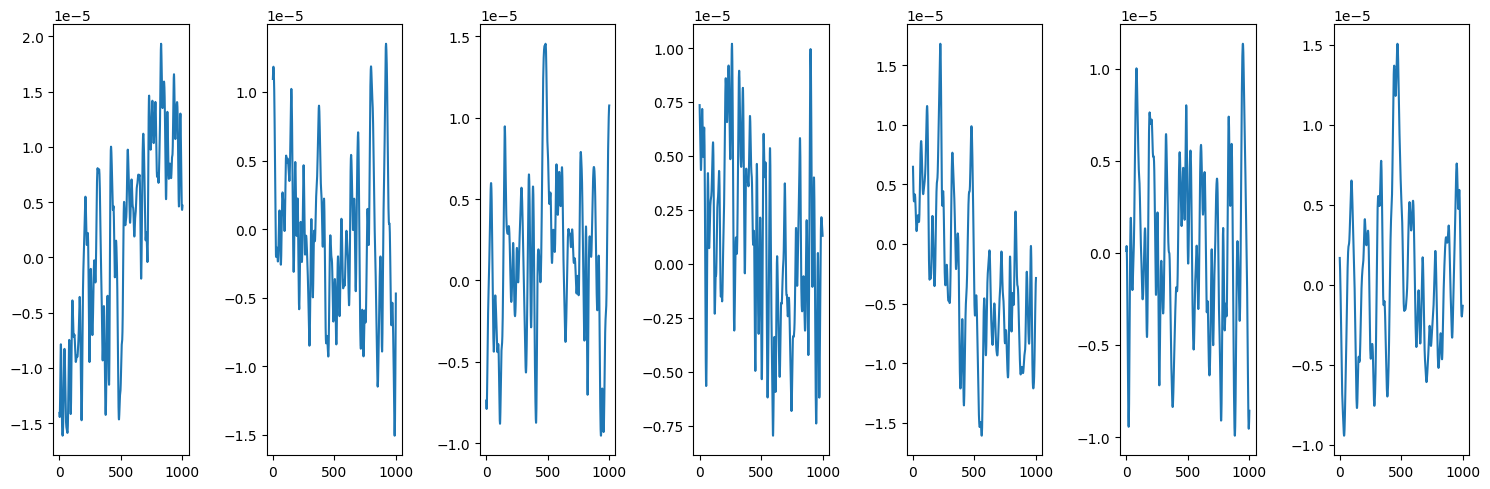

In [ ]:
import os
import mne
import matplotlib.pyplot as plt

# Base directory path
data_path = '/Users/naryeongkim/Library/CloudStorage/GoogleDrive-naryeong@stanford.edu/.shortcut-targets-by-id/1m04VeeG7WjI5Bl2ycfmDYHqwspBbhyj0/Milan_CCEPs/code/Momi_epoched/sub-01/eeg/sub-01_run-06_epoched.fif'

# Function to process and plot each epoch
def process_and_plot_epoch(file_path):
    epoched = mne.read_epochs(file_path, verbose=False)
    data = epoched.get_data()
    print(f"File: {os.path.basename(file_path)}, Data shape: {data.shape}")  # Print file name and shape of the data array
    return data  # Return the actual data

# Function to process all epochs for a given subject
def process_all_epochs_for_subject(subject_num):
    directory_path = os.path.join(base_directory_path, f'sub-{subject_num:02d}/eeg')
    fif_files = [os.path.join(directory_path, f) for f in os.listdir(directory_path) if 'sub-01_run' in f and f.endswith('.fif')]

    if not fif_files:
        print(f"No .fif files found for subject {subject_num}")
        return None

    data_list = []
    for file_path in fif_files:
        data = process_and_plot_epoch(file_path)
        data_list.append(data)

    return data_list

# Create a large figure to hold all the smaller plots
total_subjects = 1
plt.figure(figsize=(15, total_subjects * 5))

# Process and plot data for each subject
for subject_num in range(1, total_subjects + 1):
    subject_data = process_all_epochs_for_subject(subject_num)
    if subject_data:
        for i, data in enumerate(subject_data):
            plt.subplot(total_subjects, len(subject_data), (subject_num - 1) * len(subject_data) + i + 1)
            # Assuming the data is 2D, plot the first channel as an example
            plt.plot(data[0, 0, :])  # Adjust the indices based on your data's shape

plt.tight_layout()
plt.show()


In [ ]:
evoked.info

Measurement date,Unknown
Experimenter,Unknown
Participant,Unknown
Digitized points,188 points
Good channels,131 EEG
Bad channels,"e1, e9, e10, e12, e14, e24, e31, e32, e37, e45, e46, e47, e48, e49, e53, e54, e55, e56, e58, e61, e62, e63, e64, e66, e67, e68, e69, e70, e72, e74, e75, e76, e80, e81, e83, e94, e101, e105, e106, e119, e132, e144, e163, e171, e173, e185, e186, e195, e202, e205, e206, e210, e211, e222"
EOG channels,Not available
ECG channels,Not available
Sampling frequency,1000.00 Hz
Highpass,0.00 Hz
Lowpass,500.00 Hz


File: sub-01_run-05_epoched.fif, Data shape: (34, 185, 1001)
File: sub-01_run-06_epoched.fif, Data shape: (35, 185, 1001)
File: sub-01_run-03_epoched.fif, Data shape: (35, 185, 1001)
File: sub-01_run-04_epoched.fif, Data shape: (37, 185, 1001)
File: sub-01_run-01_epoched.fif, Data shape: (36, 185, 1001)
File: sub-01_run-02_epoched.fif, Data shape: (32, 185, 1001)
File: sub-01_run-07_epoched.fif, Data shape: (36, 185, 1001)


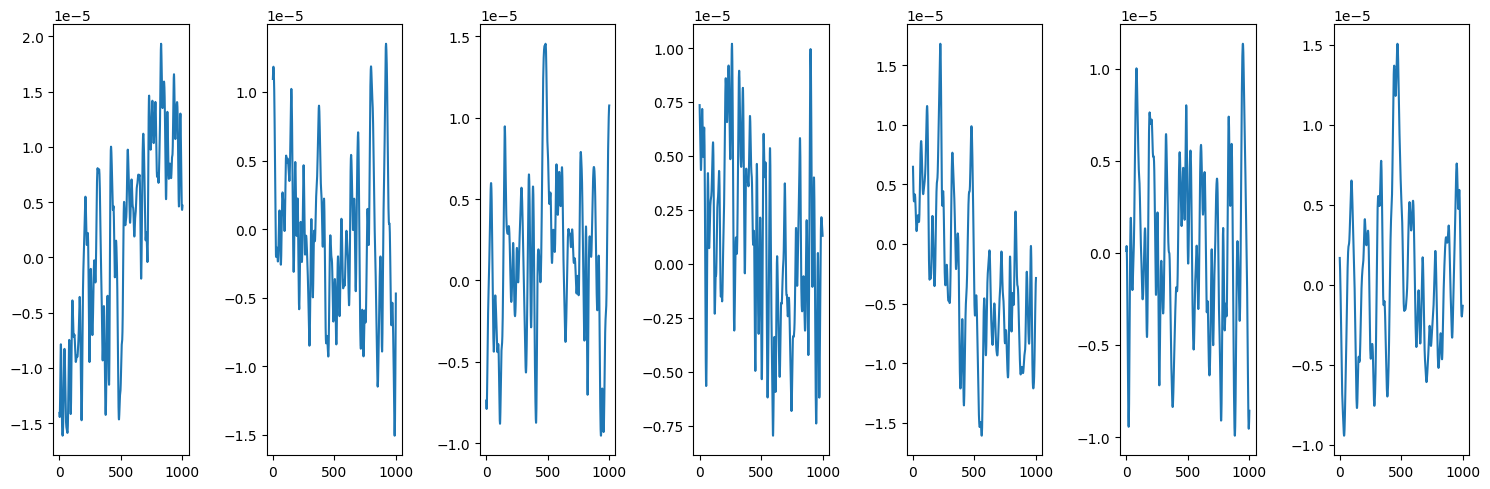

In [ ]:
import os
import mne
import matplotlib.pyplot as plt

# Base directory path
data_path = '/Users/naryeongkim/Library/CloudStorage/GoogleDrive-naryeong@stanford.edu/.shortcut-targets-by-id/1m04VeeG7WjI5Bl2ycfmDYHqwspBbhyj0/Milan_CCEPs/code/Momi_epoched/sub-01/ieeg/sub-01_run-06_epoched.fif'

# Function to process and plot each epoch
def process_and_plot_epoch(file_path):
    epoched = mne.read_epochs(file_path, verbose=False)
    data = epoched.get_data()
    print(f"File: {os.path.basename(file_path)}, Data shape: {data.shape}")  # Print file name and shape of the data array
    return data  # Return the actual data

# Function to process all epochs for a given subject
def process_all_epochs_for_subject(subject_num):
    directory_path = os.path.join(base_directory_path, f'sub-{subject_num:02d}/eeg')
    fif_files = [os.path.join(directory_path, f) for f in os.listdir(directory_path) if 'sub-01_run' in f and f.endswith('.fif')]

    if not fif_files:
        print(f"No .fif files found for subject {subject_num}")
        return None

    data_list = []
    for file_path in fif_files:
        data = process_and_plot_epoch(file_path)
        data_list.append(data)

    return data_list

# Create a large figure to hold all the smaller plots
total_subjects = 1
plt.figure(figsize=(15, total_subjects * 5))

# Process and plot data for each subject
for subject_num in range(1, total_subjects + 1):
    subject_data = process_all_epochs_for_subject(subject_num)
    if subject_data:
        for i, data in enumerate(subject_data):
            plt.subplot(total_subjects, len(subject_data), (subject_num - 1) * len(subject_data) + i + 1)
            # Assuming the data is 2D, plot the first channel as an example
            plt.plot(data[0, 0, :])  # Adjust the indices based on your data's shape

plt.tight_layout()
plt.show()


In [ ]:
import numpy as np

# Function to calculate the AUC for specific time frames
def calculate_auc(data, start_ms, end_ms, sampling_rate):
    start_idx = int(start_ms * sampling_rate / 1000)  # Convert milliseconds to indices
    end_idx = int(end_ms * sampling_rate / 1000)
    auc = np.trapz(data[:, :, start_idx:end_idx], dx=1/sampling_rate, axis=2)  # AUC calculation
    return auc

# Assuming a sampling rate of 1000 Hz (adjust this based on your actual data)
sampling_rate = 1000

# Process and plot data for each subject
for subject_num in range(1, total_subjects + 1):
    subject_data = process_all_epochs_for_subject(subject_num)
    if subject_data:
        for i, data in enumerate(subject_data):
            # Calculate AUC for each time frame
            auc_10_50 = calculate_auc(data, 10, 50, sampling_rate)
            auc_50_250 = calculate_auc(data, 50, 250, sampling_rate)

            print(f"Subject {subject_num}, File {i+1}, AUC 10-50ms: {auc_10_50.mean()}")
            print(f"Subject {subject_num}, File {i+1}, AUC 50-250ms: {auc_50_250.mean()}")

            # Existing plotting code
            #plt.subplot(total_subjects, len(subject_data), (subject_num - 1) * len(subject_data) + i + 1)
            #plt.plot(data[0, 0, :])  # Adjust the indices based on your data's shape

plt.tight_layout()
plt.show()


File: sub-01_run-05_epoched.fif, Data shape: (40, 139, 1001)
File: sub-01_run-06_epoched.fif, Data shape: (40, 139, 1001)
File: sub-01_run-03_epoched.fif, Data shape: (42, 139, 1001)
File: sub-01_run-04_epoched.fif, Data shape: (40, 139, 1001)
File: sub-01_run-01_epoched.fif, Data shape: (40, 139, 1001)
File: sub-01_run-02_epoched.fif, Data shape: (40, 139, 1001)
File: sub-01_run-07_epoched.fif, Data shape: (40, 139, 1001)
Subject 1, File 1, AUC 10-50ms: 1.0584948489234408e-07
Subject 1, File 1, AUC 50-250ms: 5.370744300725867e-07
Subject 1, File 2, AUC 10-50ms: -3.18189291615425e-08
Subject 1, File 2, AUC 50-250ms: 1.1229771610287864e-07
Subject 1, File 3, AUC 10-50ms: 4.458222217604837e-08
Subject 1, File 3, AUC 50-250ms: 1.8417209313999584e-07
Subject 1, File 4, AUC 10-50ms: 1.7356881475338773e-08
Subject 1, File 4, AUC 50-250ms: -1.583672959155385e-08
Subject 1, File 5, AUC 10-50ms: 2.36210794223561e-08
Subject 1, File 5, AUC 50-250ms: 1.1615690742875562e-07
Subject 1, File 6, AUC 

<Figure size 640x480 with 0 Axes>

File: sub-01_run-05_epoched.fif, Data shape: (40, 139, 1001)
File: sub-01_run-06_epoched.fif, Data shape: (40, 139, 1001)
File: sub-01_run-03_epoched.fif, Data shape: (42, 139, 1001)
File: sub-01_run-04_epoched.fif, Data shape: (40, 139, 1001)
File: sub-01_run-01_epoched.fif, Data shape: (40, 139, 1001)
File: sub-01_run-02_epoched.fif, Data shape: (40, 139, 1001)
File: sub-01_run-07_epoched.fif, Data shape: (40, 139, 1001)
Data at index (1, 1, 1): -2.63649235421326e-05


<Figure size 1500x500 with 0 Axes>

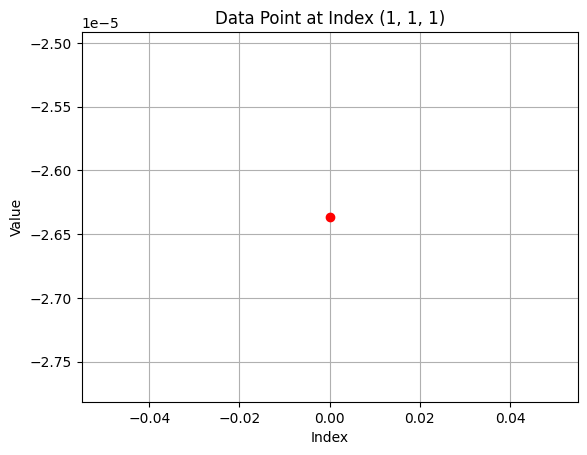

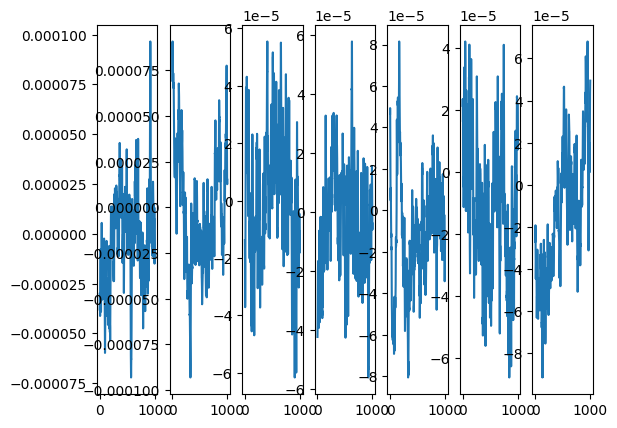

In [ ]:
import os
import mne
import matplotlib.pyplot as plt

# Base directory path
base_directory_path = '/Users/naryeongkim/Library/CloudStorage/GoogleDrive-naryeong@stanford.edu/.shortcut-targets-by-id/1m04VeeG7WjI5Bl2ycfmDYHqwspBbhyj0/Milan_CCEPs/code/Momi_epoched'

# Function to process and plot each epoch
def process_and_plot_epoch(file_path):
    epoched = mne.read_epochs(file_path, verbose=False)
    data = epoched.get_data()
    print(f"File: {os.path.basename(file_path)}, Data shape: {data.shape}")  # Print file name and shape of the data array
    return data  # Return the actual data

# Function to process all epochs for a given subject
def process_all_epochs_for_subject(subject_num):
    directory_path = os.path.join(base_directory_path, f'sub-{subject_num:02d}/ieeg')
    fif_files = [os.path.join(directory_path, f) for f in os.listdir(directory_path) if 'sub-01_run' in f and f.endswith('.fif')]

    if not fif_files:
        print(f"No .fif files found for subject {subject_num}")
        return None

    data_list = []
    for file_path in fif_files:
        data = process_and_plot_epoch(file_path)
        data_list.append(data)

    return data_list

# Function to access and plot a specific data point
def plot_specific_data_point(data, epoch_idx, channel_idx, time_idx):
    specific_data_point = data[epoch_idx, channel_idx, time_idx]
    print(f"Data at index ({epoch_idx}, {channel_idx}, {time_idx}): {specific_data_point}")
    plt.figure()
    plt.plot(specific_data_point, 'ro')  # Plot as a red dot
    plt.title(f"Data Point at Index ({epoch_idx}, {channel_idx}, {time_idx})")
    plt.xlabel('Index')
    plt.ylabel('Value')
    plt.grid(True)
    plt.show()

# Create a large figure to hold all the smaller plots
total_subjects = 1
plt.figure(figsize=(15, total_subjects * 5))

# Process and plot data for each subject
for subject_num in range(1, total_subjects + 1):
    subject_data = process_all_epochs_for_subject(subject_num)
    if subject_data:
        # Access and plot the specific data point for the first file
        plot_specific_data_point(subject_data[0], 1, 1, 1)
        for i, data in enumerate(subject_data):
            plt.subplot(total_subjects, len(subject_data), (subject_num - 1) * len(subject_data) + i + 1)
            # Assuming the data is 2D, plot the first channel as an example
            plt.plot(data[0, 0, :])  # Adjust the indices based on your data's shape

plt.tight_layout()
plt.show()


In [ ]:
import os
import mne
import matplotlib.pyplot as plt

# Base directory path - replace with your actual directory path
base_directory_path = '/Users/naryeongkim/Library/CloudStorage/GoogleDrive-naryeong@stanford.edu/.shortcut-targets-by-id/1m04VeeG7WjI5Bl2ycfmDYHqwspBbhyj0/Milan_CCEPs/code/Momi_epoched'

# Function to process and plot each epoch
def process_and_plot_epoch(file_path):
    epoched = mne.read_epochs(file_path, verbose=False)
    data = epoched.get_data()
    print(f"File: {os.path.basename(file_path)}, Data shape: {data.shape}")  # This prints the file name and shape of the data array
    return data  # Return the actual data

# Function to process all epochs for a given subject
def process_all_epochs_for_subject(subject_num):
    directory_path = os.path.join(base_directory_path, f'sub-{subject_num:02d}/eeg')
    fif_files = [os.path.join(directory_path, f) for f in os.listdir(directory_path) if f.endswith('.fif')]

    if not fif_files:
        print(f"No .fif files found for subject {subject_num}")
        return None

    data_list = []
    for file_path in fif_files:
        data = process_and_plot_epoch(file_path)
        data_list.append(data)

    return data_list

# Create a large figure to hold all the smaller plots
total_subjects = 1
plt.figure(figsize=(15, total_subjects * 5))

# Process and plot data for each subject
for subject_num in range(1, total_subjects + 1):
    subject_data = process_all_epochs_for_subject(subject_num)
    if subject_data:
        for i, data in enumerate(subject_data):
            plt.subplot(total_subjects, len(subject_data), (subject_num - 1) * len(subject_data) + i + 1)
            # Assuming the data is 2D, plot the first channel as an example
            plt.plot(data[0, 0, :])  # Adjust the indices based on your data's shape

plt.tight_layout()
plt.show()


ValueError: Could not find measurement data

<Figure size 1500x500 with 0 Axes>

In [ ]:
import os
import pandas as pd

# Base directory path
base_directory_path = '/Users/naryeongkim/Library/CloudStorage/GoogleDrive-naryeong@stanford.edu/.shortcut-targets-by-id/1m04VeeG7WjI5Bl2ycfmDYHqwspBbhyj0/Milan_CCEPs/code/Momi_epoched'

# Function to count '.fif' files for a given subject
def count_fif_files_for_subject(subject_num):
    directory_path = os.path.join(base_directory_path, f'sub-{subject_num:02d}/eeg')
    if not os.path.exists(directory_path):
        print(f"Directory not found: {directory_path}")
        return subject_num, 0

    fif_files_count = len([f for f in os.listdir(directory_path) if f.endswith('_epoched.fif')])
    return subject_num, fif_files_count

# Collecting '.fif' file counts for each subject
subject_file_counts = []
total_subjects = 36
for subject_num in range(1, total_subjects + 1):
    subject_count = count_fif_files_for_subject(subject_num)
    subject_file_counts.append(subject_count)

# Creating a DataFrame for the table
df = pd.DataFrame(subject_file_counts, columns=['Subject', 'Epoch Files Count'])

# Display the table
print(df)


    Subject  Epoch Files Count
0         1                  7
1         2                 13
2         3                  9
3         4                  7
4         5                  9
5         6                  8
6         7                 10
7         8                 11
8         9                  2
9        10                  4
10       11                  7
11       12                 17
12       13                  3
13       14                  8
14       15                 16
15       16                  8
16       17                 10
17       18                 10
18       19                  6
19       20                  9
20       21                 17
21       22                 11
22       23                  9
23       24                 13
24       25                  5
25       26                 10
26       27                  5
27       28                  4
28       29                 11
29       30                 10
30       31                  3
31      

In [ ]:
import mne

# Load your epoched data
base_directory_path = '/Users/naryeongkim/Library/CloudStorage/GoogleDrive-naryeong@stanford.edu/.shortcut-targets-by-id/1m04VeeG7WjI5Bl2ycfmDYHqwspBbhyj0/Milan_CCEPs/code/Momi_epoched/sub-01/ieeg/sub-01_run-06_epoched.fif'

epoched = mne.read_epochs(base_directory_path, verbose=False)

# Accessing sensor locations
sensor_locs = epoched.info['chs']

# Extracting the coordinates
coords = []
for ch in sensor_locs:
    loc = ch['loc'][:3]  # The first 3 elements are the x, y, z coordinates
    coords.append(loc)

print(coords)

# coords now contains the coordinates of each sensor


[array([-0.00323861, -0.04097013,  0.04184147]), array([-0.00656861, -0.04124013,  0.04184147]), array([-0.01023861, -0.04142013,  0.04134146]), array([-0.02765861, -0.04267013,  0.04084146]), array([-0.04140861, -0.04369013,  0.03984147]), array([-0.04489861, -0.04392013,  0.03984147]), array([-0.04833861, -0.04411013,  0.03934146]), array([-0.05182861, -0.04437013,  0.03934146]), array([-0.05519861, -0.04456013,  0.03934146]), array([-0.01891861,  0.00303988, -0.01722854]), array([-0.02239861,  0.00311988, -0.01722854]), array([-0.02591861,  0.00311988, -0.01722854]), array([-0.02940861,  0.00292988, -0.01722854]), array([-0.03285861,  0.00277988, -0.01722854]), array([-0.03633861,  0.00261988, -0.01722854]), array([-0.03985861,  0.00250988, -0.01722854]), array([-0.04345861,  0.00254988, -0.01722854]), array([-0.01741861, -0.00943013, -0.00285854]), array([-0.02097861, -0.00920013, -0.00285854]), array([-0.02421861, -0.00896013, -0.00335854]), array([-0.02763861, -0.00863013, -0.003

In [ ]:
import mne

# Path to your transformation file
trans_path  = '/Users/naryeongkim/Library/CloudStorage/GoogleDrive-naryeong@stanford.edu/.shortcut-targets-by-id/1m04VeeG7WjI5Bl2ycfmDYHqwspBbhyj0/Milan_CCEPs/code/Momi_epoched/sub-01/eeg/sub-01-trans.fif'


# Load the transformation data
trans = mne.read_trans(trans_path)

# Now you can inspect the transformation data
print(trans)


<Transform | head->MRI (surface RAS)>
[[ 0.99999762  0.00169335 -0.00137826  0.00047292]
 [-0.00169017  0.99999595  0.00230265  0.00005027]
 [ 0.00138216 -0.00230031  0.99999642 -0.00175694]
 [ 0.          0.          0.          1.        ]]


In [ ]:
import os
import mne
import pandas as pd

# Base directory path
base_directory_path = '/Users/naryeongkim/Library/CloudStorage/GoogleDrive-naryeong@stanford.edu/.shortcut-targets-by-id/1m04VeeG7WjI5Bl2ycfmDYHqwspBbhyj0/Milan_CCEPs/code/Momi_epoched'

# Function to count '.fif' files and get their dimensions for a given subject
def count_and_get_dimensions_fif_files_for_subject(subject_num):
    directory_path = os.path.join(base_directory_path, f'sub-{subject_num:02d}/eeg')
    if not os.path.exists(directory_path):
        print(f"Directory not found: {directory_path}")
        return subject_num, 0, []

    fif_files = [f for f in os.listdir(directory_path) if f.endswith('_epoched.fif')]
    fif_files_count = len(fif_files)
    dimensions = []

    for file in fif_files:
        file_path = os.path.join(directory_path, file)
        epoched = mne.read_epochs(file_path, verbose=False)
        dimensions.append(epoched.get_data().shape)

    return subject_num, fif_files_count, dimensions

# Collecting '.fif' file counts and dimensions for each subject
subject_file_data = []
total_subjects = 36
for subject_num in range(1, total_subjects + 1):
    subject_data = count_and_get_dimensions_fif_files_for_subject(subject_num)
    subject_file_data.append(subject_data)

# Creating a DataFrame for the table
df = pd.DataFrame(subject_file_data, columns=['Subject', 'Epoch Files Count', 'Dimensions'])

# Display the table
print(df)


    Subject  Epoch Files Count  \
0         1                  7   
1         2                 13   
2         3                  9   
3         4                  7   
4         5                  9   
5         6                  8   
6         7                 10   
7         8                 11   
8         9                  2   
9        10                  4   
10       11                  7   
11       12                 17   
12       13                  3   
13       14                  8   
14       15                 16   
15       16                  8   
16       17                 10   
17       18                 10   
18       19                  6   
19       20                  9   
20       21                 17   
21       22                 11   
22       23                  9   
23       24                 13   
24       25                  5   
25       26                 10   
26       27                  5   
27       28                  4   
28       29   

In [ ]:
import os
import mne
import pandas as pd

# Base directory path
base_directory_path = '/Users/naryeongkim/Library/CloudStorage/GoogleDrive-naryeong@stanford.edu/.shortcut-targets-by-id/1m04VeeG7WjI5Bl2ycfmDYHqwspBbhyj0/Milan_CCEPs/code/Momi_epoched'

# Function to count '.fif' files and get their dimensions for a given subject
def count_and_get_dimensions_fif_files_for_subject(subject_num):
    directory_path = os.path.join(base_directory_path, f'sub-{subject_num:02d}/ieeg')
    if not os.path.exists(directory_path):
        print(f"Directory not found: {directory_path}")
        return subject_num, 0, []

    fif_files = [f for f in os.listdir(directory_path) if f.endswith('_epoched.fif')]
    fif_files_count = len(fif_files)
    dimensions = []

    for file in fif_files:
        file_path = os.path.join(directory_path, file)
        epoched = mne.read_epochs(file_path, verbose=False)
        dimensions.append(epoched.get_data().shape)

    return subject_num, fif_files_count, dimensions

# Collecting '.fif' file counts and dimensions for each subject
subject_file_data = []
total_subjects = 36
for subject_num in range(1, total_subjects + 1):
    subject_data = count_and_get_dimensions_fif_files_for_subject(subject_num)
    subject_file_data.append(subject_data)

# Creating a DataFrame for the table
df = pd.DataFrame(subject_file_data, columns=['Subject', 'Epoch Files Count', 'Dimensions'])

# Display the table
print(df)


    Subject  Epoch Files Count  \
0         1                  7   
1         2                 13   
2         3                  9   
3         4                  7   
4         5                  9   
5         6                  8   
6         7                 10   
7         8                 11   
8         9                  2   
9        10                  4   
10       11                  7   
11       12                 17   
12       13                  3   
13       14                  8   
14       15                 16   
15       16                  8   
16       17                 10   
17       18                 10   
18       19                  6   
19       20                  9   
20       21                 17   
21       22                 11   
22       23                  9   
23       24                 13   
24       25                  5   
25       26                 10   
26       27                  5   
27       28                  4   
28       29   